# Security Insider Lab 3 — Tasks 1–3

**Group 7:** Mohamed Helaly (118043) and Abdelrahman Salama (118496)  
**Input:** the preprocessed dataset from Lab 2 (`ddos_top20_scaled.csv`, the 20 best features selected with SelectKBest) and its feature ranking (`feature_scores.csv`), both produced by our Lab 2 `preprocess.py`.  
**Positive class:** DDoS (`Label = 1`).

Run all cells in order. The notebook implements the five requested classical classifiers (Task 1) and three neural networks (Task 2), and compares all eight on the **same evaluation split** (Task 3). It writes a comparison CSV and figures to `artifacts/`.

**Method note.** The supplied preprocessing script selected features and fitted MinMax scaling before the split. Its output is used as requested; the test metrics therefore have preprocessing leakage. Rows with conflicting labels for the same 20-feature signature and exact duplicate rows are removed before splitting. **Every remaining row is used; there is no sample-size cap.** The LSTM and CNN process the ordered 20-feature vector, not a genuine packet time series.

## Setup and reproducibility

In [1]:
from pathlib import Path
import json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

ROOT = Path.cwd()
ARTIFACTS = ROOT / 'artifacts'
ARTIFACTS.mkdir(exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
plt.style.use('seaborn-v0_8-whitegrid')
print('PyTorch:', torch.__version__, '| device: CPU | seed:', SEED)

PyTorch: 2.15.0 | device: CPU | seed: 42


## Data: the preprocessed Lab 2 dataset with the same 20 best features

In [2]:
data = pd.read_csv(ROOT / 'ddos_top20_scaled.csv')
ranking = pd.read_csv(ROOT / 'feature_scores.csv')
feature_names = ranking['feature'].head(20).tolist()
assert list(data.columns) == feature_names + ['Label'], 'The two preprocessing outputs do not match.'
assert set(data['Label'].unique()) == {0, 1}
assert np.isfinite(data[feature_names].to_numpy()).all()
raw_count = len(data)
raw_labels = data['Label'].value_counts().sort_index().to_dict()
exact_duplicates = int(data.duplicated().sum())

# Remove contradictory feature signatures, then exact duplicates. No sampling.
signature = pd.util.hash_pandas_object(data[feature_names], index=False)
label_count = data.groupby(signature)['Label'].transform('nunique')
ambiguous_rows = int((label_count > 1).sum())
data = data.loc[label_count == 1].drop_duplicates().reset_index(drop=True)
removed_duplicate_rows = raw_count - ambiguous_rows - len(data)
X = data[feature_names].to_numpy(dtype=np.float32)
y = data['Label'].to_numpy(dtype=np.int64)
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.125, stratify=y_trainval, random_state=SEED)
assert len(X_train) + len(X_val) + len(X_test) == len(data)
summary = {'source_rows':raw_count, 'source_labels':raw_labels,
           'exact_duplicate_rows':exact_duplicates, 'ambiguous_rows':ambiguous_rows,
           'duplicate_rows_removed_after_ambiguity':removed_duplicate_rows,
           'rows_used':len(data), 'sample_cap':None,
           'feature_count':len(feature_names), 'features':feature_names,
           'split_sizes':{'train':len(y_train),'validation':len(y_val),'test':len(y_test)},
           'split_positive':{'train':int(y_train.sum()),'validation':int(y_val.sum()),
                             'test':int(y_test.sum())}, 'seed':SEED,
           'split_method':'Stratified 70/10/20 after ambiguity and duplicate removal'}
(ARTIFACTS / 'data_summary.json').write_text(json.dumps(summary, indent=2))
print(json.dumps({k:v for k,v in summary.items() if k != 'features'}, indent=2))
display(ranking.head(20))

{
  "source_rows": 225711,
  "source_labels": {
    "0": 97686,
    "1": 128025
  },
  "exact_duplicate_rows": 76822,
  "ambiguous_rows": 1408,
  "duplicate_rows_removed_after_ambiguity": 75424,
  "rows_used": 148879,
  "sample_cap": null,
  "feature_count": 20,
  "split_sizes": {
    "train": 104215,
    "validation": 14888,
    "test": 29776
  },
  "split_positive": {
    "train": 56843,
    "validation": 8121,
    "test": 16241
  },
  "seed": 42,
  "split_method": "Stratified 70/10/20 after ambiguity and duplicate removal"
}


,rank,feature,score
0,1,Bwd Packet Length Mean,129134.740731
1,2,Bwd Packet Length Max,112817.241584
2,3,Bwd Packet Length Std,112136.800389
3,4,Destination Port,79246.991730
4,5,Protocol,64704.694367
5,6,URG Flag Count,61687.042746
6,7,Packet Length Mean,58669.448338
7,8,Average Packet Size,58405.751420
8,9,Packet Length Std,55321.821218
9,10,Min Packet Length,50469.671242


## Task 1 — five classical machine learning classifiers

The requested models are Gaussian Naive Bayes, Gradient Boosting, AdaBoost, K-Nearest Neighbors, and a linear Support Vector Machine. The linear SVM scales to the full dataset. All models use the same training rows and are evaluated on the same held-out test rows. Scores are continuous probabilities, except for the SVM's decision function, which is valid for ROC ranking.

In [3]:
models = {
    'Gaussian NB': GaussianNB(),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=SEED),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=SEED),
    'KNN': KNeighborsClassifier(n_neighbors=7, algorithm='kd_tree', n_jobs=4),
    'SVM (linear)': LinearSVC(dual=False, random_state=SEED),
}
results = {}
for name, model in models.items():
    started = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - started
    pred = model.predict(X_test).astype(int)
    score = (model.decision_function(X_test) if name == 'SVM (linear)'
             else model.predict_proba(X_test)[:, 1])
    results[name] = {'prediction':pred, 'score':score,
                     'fit_seconds':fit_seconds, 'kind':'classical'}
    print(f'{name:22s} fit={fit_seconds:6.1f}s  F1={f1_score(y_test, pred):.4f}')

Gaussian NB            fit=   0.0s  F1=0.9999


Gradient Boosting      fit=   9.3s  F1=1.0000


AdaBoost               fit=   3.8s  F1=0.9999


KNN                    fit=   0.0s  F1=0.9997
SVM (linear)           fit=   0.1s  F1=0.9996


## Task 2 — neural networks and deep learning

The MLP uses dense layers. The LSTM and 1D CNN receive the **20 selected feature values** in the fixed order of `feature_scores.csv`. This order is a tabular feature order, not a temporal sequence, so these architectures should be interpreted as comparisons on tabular data. A stratified validation partition is reserved for early stopping; test rows are never used to train or select an epoch.

In [4]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(20, 64), nn.ReLU(), nn.Dropout(0.10),
                                 nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

class LSTMNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.LSTM(input_size=1, hidden_size=20, batch_first=True)
        self.head = nn.Linear(20, 1)
    def forward(self, x):
        _, (hidden, _) = self.rnn(x.unsqueeze(-1))
        return self.head(hidden[-1]).squeeze(-1)

class CNN1D(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(1, 16, 3, padding=1), nn.ReLU(),
                                 nn.MaxPool1d(2), nn.Conv1d(16, 32, 3, padding=1),
                                 nn.ReLU(), nn.AdaptiveAvgPool1d(5), nn.Flatten(),
                                 nn.Linear(160, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        return self.net(x.unsqueeze(1)).squeeze(-1)

def train_network(model, X_train, y_train, X_val, y_val, max_epochs=15, patience=3):
    train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train.astype(np.float32)))
    loader = DataLoader(train_ds, batch_size=512, shuffle=True)
    val_x = torch.from_numpy(X_val)
    val_y = torch.from_numpy(y_val.astype(np.float32))
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.BCEWithLogitsLoss()
    best_loss, best_state, stale = float('inf'), None, 0
    history = []
    for epoch in range(1, max_epochs + 1):
        model.train()
        total_loss = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(val_x), val_y).item()
        history.append({'epoch':epoch, 'train_loss':total_loss/len(train_ds),
                        'val_loss':val_loss})
        if val_loss < best_loss - 1e-4:
            best_loss = val_loss
            best_state = {k:v.detach().clone() for k,v in model.state_dict().items()}
            stale = 0
        else:
            stale += 1
            if stale >= patience:
                break
    model.load_state_dict(best_state)
    return history

def network_scores(model, X):
    model.eval()
    with torch.no_grad():
        chunks = [torch.sigmoid(model(torch.from_numpy(chunk))).numpy()
                  for chunk in np.array_split(X, max(1, int(np.ceil(len(X)/1024))))]
    return np.concatenate(chunks)

network_history = {}
for name, model in [('MLP', MLP()), ('LSTM', LSTMNet()), ('CNN', CNN1D())]:
    torch.manual_seed(SEED)
    started = time.perf_counter()
    history = train_network(model, X_train, y_train, X_val, y_val)
    fit_seconds = time.perf_counter() - started
    score = network_scores(model, X_test)
    pred = (score >= 0.5).astype(int)
    results[name] = {'prediction':pred, 'score':score,
                     'fit_seconds':fit_seconds, 'kind':'neural'}
    network_history[name] = history
    print(f'{name:22s} epochs={len(history):2d} fit={fit_seconds:6.1f}s  F1={f1_score(y_test, pred):.4f}')
(ARTIFACTS / 'network_history.json').write_text(json.dumps(network_history, indent=2))

MLP                    epochs=15 fit=   3.7s  F1=0.9997


LSTM                   epochs= 9 fit=  11.5s  F1=0.9962


CNN                    epochs=15 fit=  47.6s  F1=0.9995


4434

## Task 3 — compare accuracy, F1, precision, recall, and ROC curves

In [5]:
rows = []
for name, record in results.items():
    pred, score = record['prediction'], record['score']
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0,1]).ravel()
    rows.append({'Model':name, 'Type':record['kind'],
                 'Accuracy':accuracy_score(y_test, pred),
                 'F1':f1_score(y_test, pred, zero_division=0),
                 'Precision':precision_score(y_test, pred, zero_division=0),
                 'Recall':recall_score(y_test, pred, zero_division=0),
                 'ROC AUC':roc_auc_score(y_test, score),
                 'TN':int(tn), 'FP':int(fp), 'FN':int(fn), 'TP':int(tp),
                 'Fit seconds':record['fit_seconds']})
comparison = pd.DataFrame(rows).sort_values('F1', ascending=False).reset_index(drop=True)
comparison.to_csv(ARTIFACTS / 'comparison.csv', index=False)
display(comparison.style.format({c:'{:.4f}' for c in
        ['Accuracy','F1','Precision','Recall','ROC AUC']}).format({'Fit seconds':'{:.1f}'}))
leaders = comparison.loc[(comparison['F1'] - comparison['F1'].max()).abs() < 1e-12, 'Model'].tolist()
print('Highest F1 (tie if multiple):', ', '.join(leaders))

,Model,Type,Accuracy,F1,Precision,Recall,ROC AUC,TN,FP,FN,TP,Fit seconds
0,Gradient Boosting,classical,0.999966,0.999969,1.000000,0.999938,1.000000,13535,0,1,16240,9.3
1,Gaussian NB,classical,0.999899,0.999908,1.000000,0.999815,0.999908,13535,0,3,16238,0.0
2,AdaBoost,classical,0.999899,0.999908,1.000000,0.999815,1.000000,13535,0,3,16238,3.8
3,KNN,classical,0.999698,0.999723,0.999815,0.999631,0.999926,13532,3,6,16235,0.0
4,MLP,neural,0.999631,0.999661,0.999815,0.999507,0.999996,13532,3,8,16233,3.7
5,SVM (linear),classical,0.999530,0.999569,0.999569,0.999569,0.999872,13528,7,7,16234,0.1
6,CNN,neural,0.999496,0.999538,0.999569,0.999507,0.999997,13528,7,8,16233,47.6
7,LSTM,neural,0.995802,0.996157,0.994842,0.997476,0.999860,13451,84,41,16200,11.5


Highest F1 (tie if multiple): Gradient Boosting


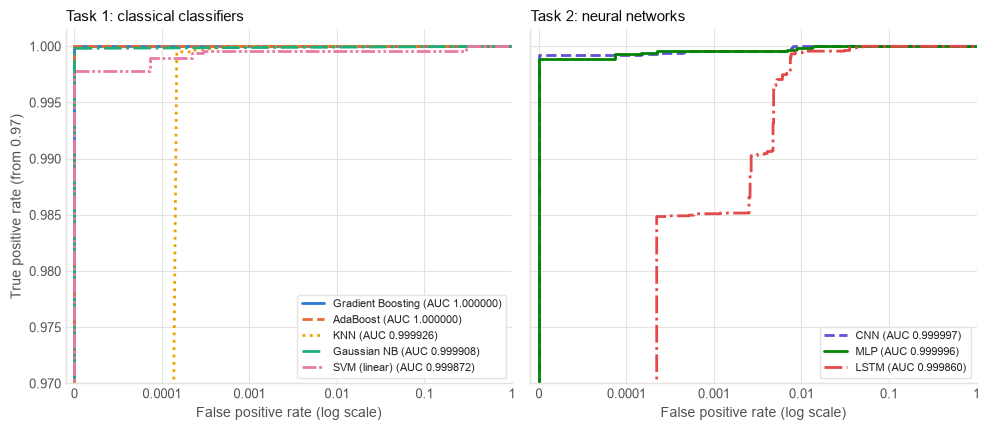

In [6]:
INK, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#ffffff'
STYLE = {  # fixed colour + line style per model (line style keeps curves apart in grey print)
    'Gradient Boosting': ('#2a78d6', '-'),  'AdaBoost': ('#eb6834', '--'),
    'Gaussian NB': ('#1baf7a', '-.'),       'KNN': ('#eda100', ':'),
    'SVM (linear)': ('#e87ba4', (0, (5, 1, 1, 1, 1, 1))),
    'MLP': ('#008300', '-'), 'CNN': ('#6250d6', '--'), 'LSTM': ('#e34948', '-.'),
}
FPR_FLOOR = 1e-5  # log axis cannot show 0: FPR = 0 is drawn at the left edge
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
fig.patch.set_facecolor(SURFACE)
for ax, kind, title in [(axes[0], 'classical', 'Task 1: classical classifiers'),
                        (axes[1], 'neural', 'Task 2: neural networks')]:
    names = sorted((n for n, r in results.items() if r['kind'] == kind),
                   key=lambda n: -roc_auc_score(y_test, results[n]['score']))
    for name in names:
        fpr, tpr, _ = roc_curve(y_test, results[name]['score'])
        auc = roc_auc_score(y_test, results[name]['score'])
        color, ls = STYLE[name]
        # straight segments between ROC points, the same interpolation that roc_auc_score uses
        ax.plot(np.maximum(fpr, FPR_FLOOR), tpr, color=color, linestyle=ls, linewidth=2,
                label=f'{name} (AUC {auc:.6f})')
    ax.set_xscale('log')
    ax.set_xlim(FPR_FLOOR * 0.8, 1)
    ax.set_ylim(0.97, 1.0015)
    ax.set_xticks([1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1], ['0', '0.0001', '0.001', '0.01', '0.1', '1'])
    ax.set_xlabel('False positive rate (log scale)', color=MUTED)
    ax.set_title(title, loc='left', fontsize=11, color=INK)
    ax.legend(loc='lower right', frameon=True, framealpha=0.95, edgecolor=GRID, fontsize=8)
    ax.set_facecolor(SURFACE)
    ax.grid(color=GRID, linewidth=0.8)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(GRID)
axes[0].set_ylabel('True positive rate (from 0.97)', color=MUTED)
fig.tight_layout()
fig.savefig(ARTIFACTS / 'roc_curves.png', dpi=180, facecolor=SURFACE)
display(fig)
plt.close(fig)



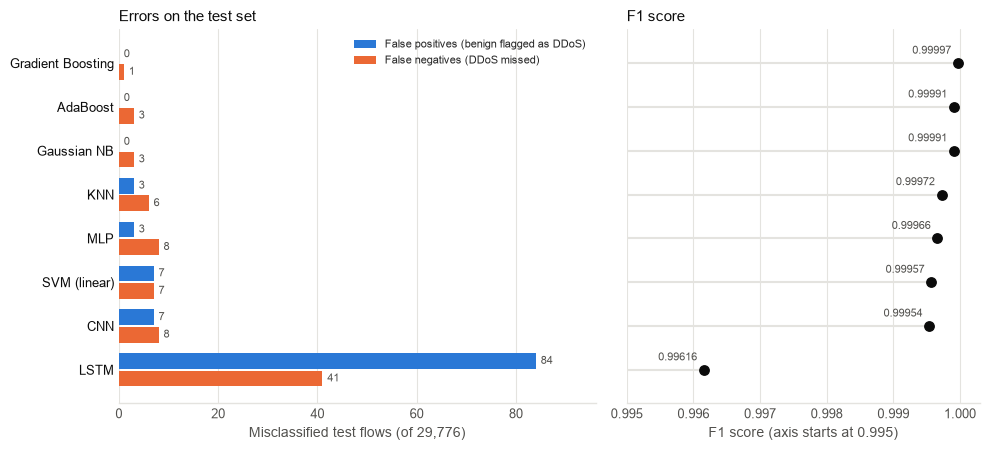

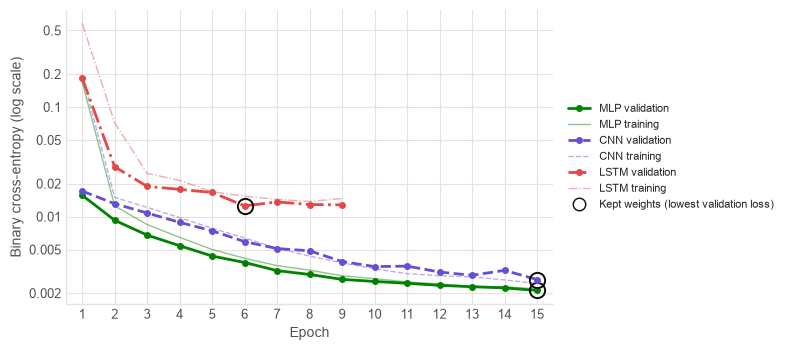

In [7]:
# Errors (FP/FN) and F1 on a zoomed axis: all scores are close to 1, so plain bars hide the differences.
INK, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#ffffff'
FP_COLOR, FN_COLOR = '#2a78d6', '#eb6834'
order = comparison.sort_values(['F1', 'Model'], ascending=[True, False]).reset_index(drop=True)
ypos = np.arange(len(order))
fig, (err_ax, f1_ax) = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True,
                                    gridspec_kw={'width_ratios': [1.35, 1]})
fig.patch.set_facecolor(SURFACE)
h = 0.36
for offset, col, color, label in [(h / 2 + 0.02, 'FP', FP_COLOR, 'False positives (benign flagged as DDoS)'),
                                  (-h / 2 - 0.02, 'FN', FN_COLOR, 'False negatives (DDoS missed)')]:
    bars = err_ax.barh(ypos + offset, order[col], height=h, color=color, label=label)
    for bar, value in zip(bars, order[col]):
        err_ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f'{value}',
                    va='center', ha='left', fontsize=8, color=MUTED)
err_ax.set_xlim(0, max(order['FP'].max(), order['FN'].max()) * 1.12 + 2)
err_ax.set_xlabel('Misclassified test flows (of 29,776)', color=MUTED)
err_ax.set_title('Errors on the test set', loc='left', fontsize=11, color=INK)
err_ax.legend(loc='upper right', frameon=False, fontsize=8)

f1_ax.hlines(ypos, 0.995, order['F1'], color=GRID, linewidth=1.5, zorder=1)
f1_ax.scatter(order['F1'], ypos, s=46, color=INK, zorder=2)
for y, value in zip(ypos, order['F1']):
    f1_ax.text(value - 0.00010, y + 0.28, f'{value:.5f}', ha='right', va='center',
               fontsize=8, color=MUTED)
f1_ax.set_xlim(0.995, 1.0003)
f1_ax.set_xlabel('F1 score (axis starts at 0.995)', color=MUTED)
f1_ax.set_title('F1 score', loc='left', fontsize=11, color=INK)

err_ax.set_yticks(ypos, order['Model'])
for ax in (err_ax, f1_ax):
    ax.set_facecolor(SURFACE)
    ax.grid(axis='x', color=GRID, linewidth=0.8)
    ax.grid(axis='y', visible=False)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)
    for side in ('top', 'right', 'left'):
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(GRID)
err_ax.tick_params(axis='y', colors=INK)
fig.tight_layout()
fig.savefig(ARTIFACTS / 'metric_comparison.png', dpi=180, facecolor=SURFACE)
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 3.6))
fig.patch.set_facecolor(SURFACE)
for name in ['MLP', 'CNN', 'LSTM']:
    history = network_history[name]
    epochs = [h['epoch'] for h in history]
    color, ls = STYLE[name]
    ax.plot(epochs, [h['val_loss'] for h in history], color=color, linestyle=ls,
            linewidth=2, marker='o', markersize=4, label=f'{name} validation')
    ax.plot(epochs, [h['train_loss'] for h in history], color=color, linestyle=ls,
            linewidth=1, alpha=0.45, label=f'{name} training')
    best = min(history, key=lambda h: h['val_loss'])
    ax.plot(best['epoch'], best['val_loss'], marker='o', markersize=11, markerfacecolor='none',
            markeredgecolor=INK, markeredgewidth=1.4, linestyle='none')
ax.plot([], [], marker='o', markersize=9, markerfacecolor='none', markeredgecolor=INK,
        linestyle='none', label='Kept weights (lowest validation loss)')
ax.set_yscale('log')
ticks = [0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5]
ax.set_yticks(ticks, [f'{t:g}' for t in ticks])
ax.minorticks_off()
ax.set_xticks(range(1, 16))
ax.set_xlim(0.5, 15.5)
ax.set_xlabel('Epoch', color=MUTED)
ax.set_ylabel('Binary cross-entropy (log scale)', color=MUTED)
ax.set_facecolor(SURFACE)
ax.grid(color=GRID, linewidth=0.8)
ax.tick_params(colors=MUTED, labelsize=9, length=0)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
for side in ('left', 'bottom'):
    ax.spines[side].set_color(GRID)
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(ARTIFACTS / 'learning_curves.png', dpi=180, facecolor=SURFACE)
display(fig)
plt.close(fig)

### Task 3 — why is the LSTM weaker?

Diagnostic for the discussion: which flows the LSTM misclassifies, whether the other models get them right, and whether more training closes the gap. The retrained LSTM is only a diagnostic; Table 4.1 keeps the original LSTM.

In [8]:
from collections import Counter
lstm_pred, lstm_score = results['LSTM']['prediction'], results['LSTM']['score']
lstm_err = lstm_pred != y_test
only_lstm = lstm_err.copy()
for name, record in results.items():
    if name != 'LSTM':
        only_lstm &= record['prediction'] == y_test
# undo the min-max scaling of Destination Port (min and max taken from the raw CSV)
raw_port = pd.read_csv(ROOT / 'Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv',
                       usecols=lambda c: c.strip() == 'Destination Port').iloc[:, 0]
port = np.rint(X_test[:, feature_names.index('Destination Port')]
               * (raw_port.max() - raw_port.min()) + raw_port.min()).astype(int)
fp_mask, fn_mask = lstm_err & (y_test == 0), lstm_err & (y_test == 1)
print(f'LSTM errors: {lstm_err.sum()} (FP {fp_mask.sum()}, FN {fn_mask.sum()})')
print(f'  classified correctly by all 7 other models: {only_lstm.sum()}')
print('  destination ports of false positives:', Counter(port[fp_mask]).most_common(3))
print('  destination ports of false negatives:', Counter(port[fn_mask]).most_common(3))
print('  destination ports of all DDoS test flows:', Counter(port[y_test == 1]).most_common(3))
print(f'  false negatives with a score between 0.37 and 0.39: '
      f'{((lstm_score > 0.37) & (lstm_score < 0.39) & fn_mask).sum()}')
last = network_history['LSTM'][-1]
print(f'  last epoch: training loss {last["train_loss"]:.4f}, validation loss {last["val_loss"]:.4f}')

# Does more training help? Same LSTM, up to 40 epochs, patience 10.
torch.manual_seed(SEED)
long_lstm = LSTMNet()
long_history = train_network(long_lstm, X_train, y_train, X_val, y_val, max_epochs=40, patience=10)
long_pred = (network_scores(long_lstm, X_test) >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, long_pred).ravel()
print(f'LSTM trained up to 40 epochs: ran {len(long_history)} epochs, '
      f'best validation loss {min(h["val_loss"] for h in long_history):.4f}, '
      f'test F1 {f1_score(y_test, long_pred):.5f}, FP {fp}, FN {fn} ({fp + fn} errors)')

LSTM errors: 125 (FP 84, FN 41)
  classified correctly by all 7 other models: 109
  destination ports of false positives: [(np.int64(443), 79), (np.int64(80), 5)]
  destination ports of false negatives: [(np.int64(80), 41)]
  destination ports of all DDoS test flows: [(np.int64(80), 16241)]
  false negatives with a score between 0.37 and 0.39: 28
  last epoch: training loss 0.0146, validation loss 0.0128


LSTM trained up to 40 epochs: ran 40 epochs, best validation loss 0.0061, test F1 0.99874, FP 27, FN 14 (41 errors)


In [9]:
np.savez_compressed(ARTIFACTS / 'predictions.npz', y_test=y_test,
                    names=np.array(list(results)),
                    predictions=np.stack([r['prediction'] for r in results.values()]),
                    scores=np.stack([r['score'] for r in results.values()]))
print('Saved:', *(p.name for p in sorted(ARTIFACTS.iterdir())), sep='\n  ')

Saved:
  comparison.csv
  data_summary.json
  learning_curves.png
  metric_comparison.png
  network_history.json
  predictions.npz
  roc_curves.png
